# Import Packages

In [1]:
import pyarrow.parquet as pq 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np, cv2
from statsmodels.graphics.mosaicplot import mosaic
import plotly.express as px
import sys
import os
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))   # notebooks/ -> repo root -> src/

from data_loading import XBDParquetDataset



# Load Dataset

In [2]:
# How many events are included in each dataset?

PARQUET_DIR = Path.cwd().parent / "data" / "parquet"   # edit if your parquet files live elsewhere
files = sorted(PARQUET_DIR.glob("*.parquet")) # find all parquet files in directory
assert files, f"No .parquet files found in {PARQUET_DIR}" # test that parquet files exist 
print("Found:", [f.name for f in files]) # print found parquet files
train_file = files[2] #select training set 

Found: ['hold.parquet', 'test.parquet', 'train.parquet']


## Chart Style

In [4]:
# --- chart style ---
SURFACE, INK, INK_2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
SERIES_1 = "#2a78d6"                                                      # single-series charts
DAMAGE_COLORS = {1: "#86b6ef", 2: "#5598e7", 3: "#256abf", 4: "#104281"}  # ordered: more damage = darker
DAMAGE_NAMES = {1: "no damage", 2: "minor damage", 3: "major damage", 4: "destroyed"}

plt.rcParams.update({
    # explicit light surface, so charts look the same in light and dark notebook themes
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "xtick.color": INK, "ytick.color": INK,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "font.family": "sans-serif", "font.size": 10,
    "axes.axisbelow": 'True',
})


def hbar(series, title, xlabel, fmt="{:,.0f}"):
    """One series, one color, sorted, value at the bar tip. No legend (one series)."""
    s = series.sort_values()
    fig, ax = plt.subplots(figsize=(8, 0.32 * len(s) + 1.2))
    ax.barh(s.index, s.values, height=0.65, color=SERIES_1)
    ax.xaxis.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines["left"].set_visible(False)
    ax.tick_params(axis="y", length=0)
    for y, v in enumerate(s.values):
        ax.text(v, y, "  " + fmt.format(v), va="center", ha="left", color=INK_2, fontsize=9)
    ax.set_title(title, loc="left", color=INK, fontsize=12, pad=12)
    ax.set_xlabel(xlabel)
    ax.margins(x=0.12)
    plt.show()

# Number of samples per event in training set

In [5]:
META_COLS = ["sample_id", "disaster", "split", "height", "width"] #columns to index from parquet file
meta = pd.read_parquet(train_file, columns=META_COLS)#,ignore_index=True) # parquet to df[meta_cols] for training set 
print(f"{len(meta):,} samples, {meta['disaster'].nunique()} events")
disaster_frequency = meta.value_counts(['disaster'])   # # of samples for each event in training set 
disaster_frequency = disaster_frequency.to_frame().reset_index()
disaster_frequency


2,799 samples, 10 events


,disaster,count
0,socal-fire,823
1,hurricane-michael,343
2,hurricane-florence,319
3,hurricane-harvey,319
4,midwest-flooding,279
5,hurricane-matthew,238
6,santa-rosa-wildfire,226
7,mexico-earthquake,121
8,palu-tsunami,113
9,guatemala-volcano,18


In [6]:
meta

,sample_id,disaster,split,height,width
0,guatemala-volcano_00000000,guatemala-volcano,train,1024,1024
1,guatemala-volcano_00000001,guatemala-volcano,train,1024,1024
2,guatemala-volcano_00000002,guatemala-volcano,train,1024,1024
3,guatemala-volcano_00000006,guatemala-volcano,train,1024,1024
4,guatemala-volcano_00000007,guatemala-volcano,train,1024,1024
...,...,...,...,...,...
2794,socal-fire_00001396,socal-fire,train,1024,1024
2795,socal-fire_00001397,socal-fire,train,1024,1024
2796,socal-fire_00001398,socal-fire,train,1024,1024
2797,socal-fire_00001399,socal-fire,train,1024,1024


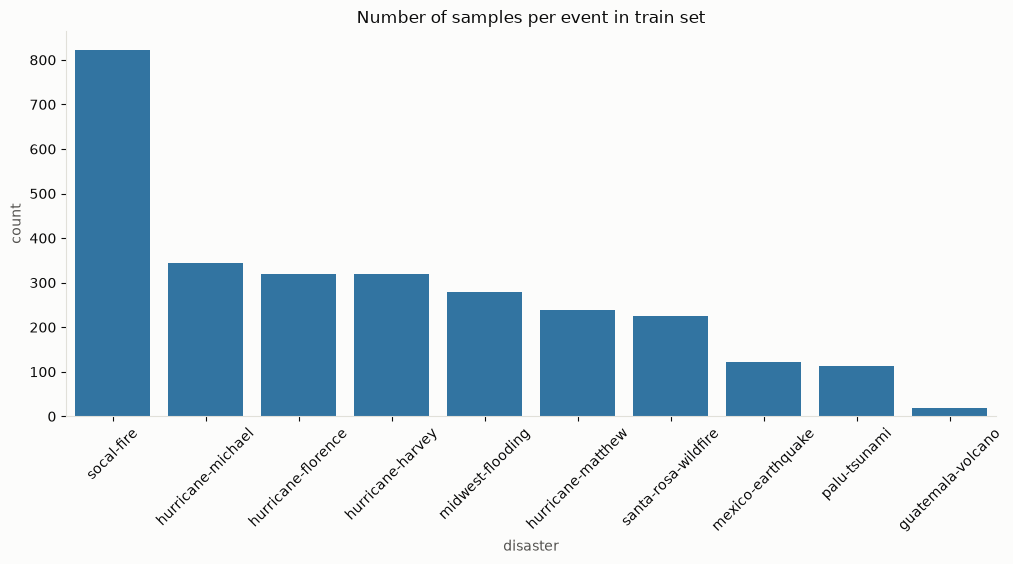

<Figure size 640x480 with 0 Axes>

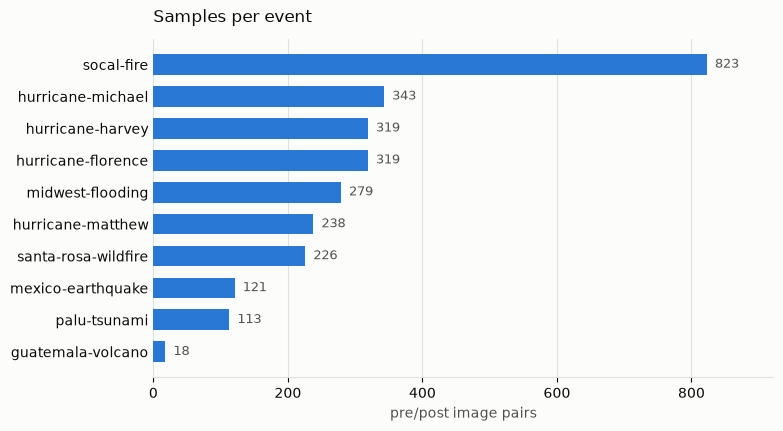

In [7]:
# Number of samples per event in training set

plt.figure(figsize=[12,5])
sns.barplot(data= disaster_frequency, x = 'disaster', y = 'count')
plt.xticks(rotation=45)
plt.title('Number of samples per event in train set')

#same thing, different orientation w counts
plt.figure()
hbar(meta["disaster"].value_counts(), "Samples per event", "pre/post image pairs")


# Are all the images the same size?

In [8]:
meta.head()

,sample_id,disaster,split,height,width
0,guatemala-volcano_00000000,guatemala-volcano,train,1024,1024
1,guatemala-volcano_00000001,guatemala-volcano,train,1024,1024
2,guatemala-volcano_00000002,guatemala-volcano,train,1024,1024
3,guatemala-volcano_00000006,guatemala-volcano,train,1024,1024
4,guatemala-volcano_00000007,guatemala-volcano,train,1024,1024


In [9]:
meta[["height", "width"]].value_counts().rename("samples").to_frame()   # are all images the same size?

,,samples
height,width,
1024,1024,2799


# Quality check for all dataset partitions

In [55]:
EXPECTED_HW = (1024, 1024)

def check_sample(pre_b, post_b, loc_b, dmg_b, expected_hw=EXPECTED_HW):
    """Return a list of problems found in one sample (empty list = looks fine)."""
    problems, arrays = [], {}
    parts = [("pre", pre_b, cv2.IMREAD_COLOR), ("post", post_b, cv2.IMREAD_COLOR),
             ("loc", loc_b, cv2.IMREAD_UNCHANGED), ("dmg", dmg_b, cv2.IMREAD_UNCHANGED)] #decode pre and post images
    for name, raw, flag in parts:
        if raw is None or len(raw) == 0: #empty tile
            problems.append(f"{name}: empty"); continue
        arr = cv2.imdecode(np.frombuffer(raw, np.uint8), flag)
        if arr is None: #problem decoding
            problems.append(f"{name}: cannot decode"); continue
        arrays[name] = arr
        if arr.shape[:2] != expected_hw: # image shape is not as expected 
            problems.append(f"{name}: size {arr.shape[:2]} != {expected_hw}")
        if name in ("pre", "post") and arr.std() == 0: 
            problems.append(f"{name}: blank (constant) image")
    if "loc" in arrays and not set(np.unique(arrays["loc"])) <= {0, 1}:
        problems.append(f"loc: unexpected values {np.unique(arrays['loc'])[:6]}")
    if "dmg" in arrays and not set(np.unique(arrays["dmg"])) <= {0, 1, 2, 3, 4}:
        problems.append(f"dmg: unexpected values {np.unique(arrays['dmg'])[:6]}")
    if "pre" in arrays and "post" in arrays and arrays["pre"].shape != arrays["post"].shape:
        problems.append("pre/post shapes differ")
    return problems


PAYLOAD = ["sample_id", "pre_image_bytes", "post_image_bytes", "localization_mask_bytes", "damage_mask_bytes"]
found = []
for f in files:
    try:
        pf = pq.ParquetFile(f)
        for batch in pf.iter_batches(batch_size=16, columns=PAYLOAD):   # small batches keep memory flat
            d = batch.to_pydict()
            for sid, pre, post, loc, dmg in zip(*(d[c] for c in PAYLOAD)):
                for p in check_sample(pre, post, loc, dmg):
                    found.append({"file": f.name, "sample_id": sid, "problem": p})
    except Exception as e:                      # a damaged parquet file/row group raises here
        found.append({"file": f.name, "sample_id": "(whole file)", "problem": repr(e)})

problems = pd.DataFrame(found, columns=["file", "sample_id", "problem"])
print(f"{len(problems)} problem(s) found")
problems

0 problem(s) found


,file,sample_id,problem


In [ ]:
meta.isna().sum()                          # missing values in sample_id / disaster / sizes

sample_id    0
disaster     0
split        0
height       0
width        0
dtype: int64

In [58]:
meta["sample_id"].duplicated().sum()       # duplicate samples (also across train/hold/test)

np.int64(0)

# Examine Parquet

In [10]:
pq.ParquetFile(train_file).metadata

  created_by: parquet-cpp-arrow version 21.0.0
  num_columns: 9
  num_rows: 2799
  num_row_groups: 1
  format_version: 2.6
  serialized_size: 10932

In [11]:
# to avoid opening every image, use parquet metadata to overview
rows = []
md_ = pq.ParquetFile(train_file).metadata
sizes = [md_.row_group(g).total_byte_size for g in range(md_.num_row_groups)] #grab image byte size for for every entry in the single row group 
rows.append({
    "file": train_file.name, "rows": md_.num_rows, "row_groups": md_.num_row_groups,
    "largest_group_GB": round(max(sizes) / 1e9, 2), "file_size_GB": round(train_file.stat().st_size / 1e9, 2),
}) # store largest image in row group in dict
pd.DataFrame(rows)

# return stats for each parquet file 

,file,rows,row_groups,largest_group_GB,file_size_GB
0,train.parquet,2799,1,8.31,8.3


# Class Balance

In [12]:
# Load in pre and post damage masks by decoding localization_mask_bytes and damage_mask_bytes

MASK_COLS = ["sample_id", "disaster", "localization_mask_bytes", "damage_mask_bytes"]


def decode(b): #take in 1d np image bytes array and return decoded np ndarray in original alpha channel 
    return cv2.imdecode(np.frombuffer(b, np.uint8), cv2.IMREAD_UNCHANGED)


def mask_stats(path):
    df = pd.read_parquet(path, columns=MASK_COLS)
    out = []
    for sid, disaster, loc_b, dmg_b in zip(df.sample_id, df.disaster, df.localization_mask_bytes, df.damage_mask_bytes):
        loc, dmg = decode(loc_b), decode(dmg_b) # decode pre and post disaster images 
        counts = np.bincount(dmg.ravel(), minlength=5) # flatten to 1D and observe range and distribution of pixel values
        out.append({
            "sample_id": sid, "disaster": disaster,
            "px_total": dmg.size,
            "px_building": int((loc == 1).sum()), #count how many buildings are in this pre-disaster mask
            **{f"class_{i}": int(counts[i]) for i in range(1, 5)}, # record # of each class in post-disaster mask
            "px_unclassified": int(((loc == 1) & (dmg == 0)).sum()), # a building in the pre-disaster mask but 0 in the damage mask = "un-classified"
        })
    return pd.DataFrame(out)


stats = mask_stats(train_file)
print(f"decoded masks for {len(stats):,} samples")

decoded masks for 2,799 samples


In [13]:
stats

,sample_id,disaster,px_total,px_building,class_1,class_2,class_3,class_4,px_unclassified
0,guatemala-volcano_00000000,guatemala-volcano,1048576,15965,15938,0,0,0,46
1,guatemala-volcano_00000001,guatemala-volcano,1048576,2567,0,2560,0,0,15
2,guatemala-volcano_00000002,guatemala-volcano,1048576,2498,0,0,0,2498,0
3,guatemala-volcano_00000006,guatemala-volcano,1048576,46737,46737,0,0,0,0
4,guatemala-volcano_00000007,guatemala-volcano,1048576,9728,9728,0,0,0,0
...,...,...,...,...,...,...,...,...,...
2794,socal-fire_00001396,socal-fire,1048576,0,0,0,0,0,0
2795,socal-fire_00001397,socal-fire,1048576,43508,43056,0,0,301,151
2796,socal-fire_00001398,socal-fire,1048576,0,0,0,0,0,0
2797,socal-fire_00001399,socal-fire,1048576,0,0,0,0,0,0


In [ ]:
# POST DISASTER STATS

g = stats.groupby(["disaster"])
class_cols = [f"class_{i}" for i in range(1, 5)]
DAMAGE_NAMES = {1: "no damage", 2: "minor damage", 3: "major damage", 4: "destroyed"}

summary = pd.DataFrame({
    "samples": g.size(), # of samples for each disaster 
    "pct_images_no_buildings": 100 * g["px_building"].apply(lambda s: (s == 0).mean()), # average ratio of no-building to buildings in each image
    "pct_pixels_building": 100 * g["px_building"].sum() / g["px_total"].sum(), # density of buildings for each disaster 
    "pct_building_unclassified": 100 * g["px_unclassified"].sum() / g["px_building"].sum(), # ratio of unclassified to buildings for each disaster
})

classified = g[class_cols].sum() # of pixels in each class for each disaster event
share = 100 * classified.div(classified.sum(axis=1), axis=0)   # % of classified building pixels per class per event
share.columns = [DAMAGE_NAMES[i] for i in range(1, 5)] 
share.reset_index(inplace = True)
print(share)

summary.round(1).sort_values(["samples"], ascending=False)   # table view
summary.reset_index(inplace = True)
summary

              disaster  no damage  minor damage  major damage  destroyed
0    guatemala-volcano  94.397488      1.571380      0.797131   3.234001
1   hurricane-florence  74.379707      6.158827     18.624221   0.837245
2     hurricane-harvey  56.498712     12.097155     30.688739   0.715395
3    hurricane-matthew  19.837178     54.591667     16.417277   9.153879
4    hurricane-michael  59.260481     23.843404     14.724836   2.171279
5    mexico-earthquake  99.402770      0.508791      0.077132   0.011306
6     midwest-flooding  96.395139      1.401577      1.705442   0.497842
7         palu-tsunami  84.265432      0.004752      3.409308  12.320509
8  santa-rosa-wildfire  69.734663      0.635522      0.864093  28.765722
9           socal-fire  91.129689      0.506667      0.472947   7.890698


,disaster,samples,pct_images_no_buildings,pct_pixels_building,pct_building_unclassified
0,guatemala-volcano,18,5.555556,2.183803,16.255559
1,hurricane-florence,319,4.075235,2.032375,3.281262
2,hurricane-harvey,319,5.956113,12.450347,1.165887
3,hurricane-matthew,238,6.302521,2.351269,3.231387
4,hurricane-michael,343,2.623907,8.168167,0.707739
5,mexico-earthquake,121,0.000000,26.971005,0.402610
6,midwest-flooding,279,12.544803,3.082848,1.685007
7,palu-tsunami,113,1.769912,16.007830,1.379789
8,santa-rosa-wildfire,226,3.097345,6.771804,0.289412
9,socal-fire,823,50.425273,1.518713,1.360902


Text(0, 0.5, '%')

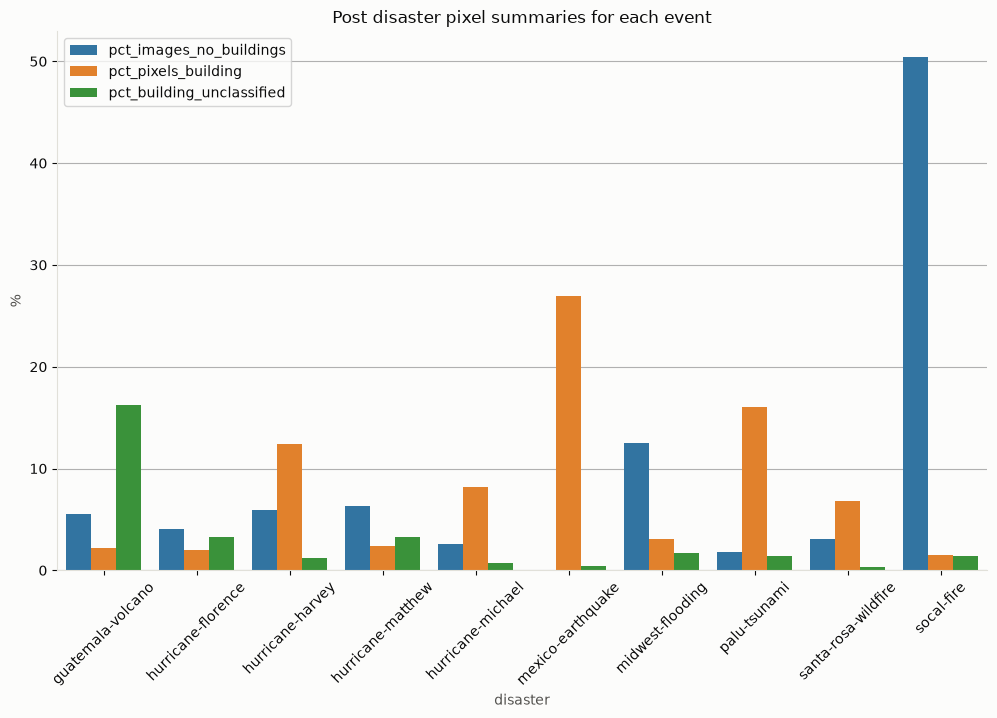

In [37]:
# Reorder dataframe for seaborn

df = summary.melt(id_vars = 'disaster', value_vars = ['pct_images_no_buildings','pct_pixels_building','pct_building_unclassified'])

# Percentage of pixels for disaster level for each event

plt.figure(figsize=[12,7])
plt.grid(True)
sns.barplot(data= df, x = 'disaster', y = 'value', hue = 'variable')
plt.xticks(rotation=45)
plt.legend(alignment = 'center')
plt.title('Post disaster pixel summaries for each event')
plt.xlabel('disaster')
plt.ylabel('%')

Text(0, 0.5, '% of pixels')

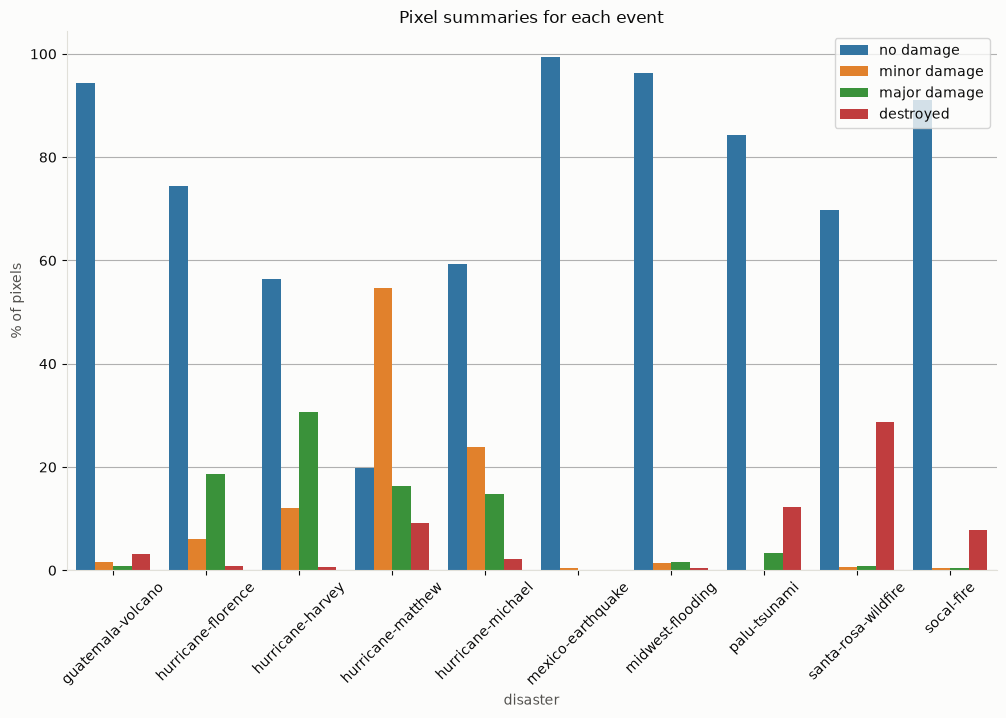

In [ ]:
# Reorder dataframe for seaborn

df = share.melt(id_vars = 'disaster', value_vars = ['no damage','minor damage','major damage','destroyed'])

# Percentage of pixels for disaster level for each event

plt.figure(figsize=[12,7])
plt.grid(True)
sns.barplot(data= df, x = 'disaster', y = 'value', hue = 'variable')
plt.xticks(rotation=45)
plt.legend(alignment = 'center')
plt.title('Percentage of pixels for disaster level for each event')
plt.xlabel('disaster')
plt.ylabel('% of pixels')


## Interactive Version

In [41]:
import plotly.graph_objects as go


def damage_tables(classified, names):
    """Per-event class counts and % shares, rows sorted so the most damaged event is on top of the chart."""
    counts = classified.copy()
    counts.columns = names
    total = counts.sum(axis=1).replace(0, np.nan)
    pct = counts.div(total, axis=0).mul(100).fillna(0)
    order = (pct[names[2]] + pct[names[3]]).sort_values().index   # ascending: Plotly draws the first row at the bottom
    return counts.loc[order], pct.loc[order]


def interactive_damage_chart(classified, names, title):
    counts, pct = damage_tables(classified, names)
    fig = go.Figure()
    for i, name in enumerate(names, start=1):
        fig.add_bar(
            y=pct.index, x=pct[name], name=name, orientation="h",
            marker=dict(color=DAMAGE_COLORS[i], line=dict(color=SURFACE, width=1.5)),   # surface-colored edge = gap between segments
            customdata=np.stack([counts[name].to_numpy()], axis=-1),
            hovertemplate="<b>%{y}</b><br>" + name + ": %{x:.1f}%<br>%{customdata[0]:,} px<extra></extra>",
        )

    pct_x = [pct[n].tolist() for n in names]
    cnt_x = [counts[n].tolist() for n in names]
    fig.update_layout(
        barmode="stack", bargap=0.35,
        title=dict(text=title, x=0, xanchor="left", font=dict(size=14, color=INK)),
        paper_bgcolor=SURFACE, plot_bgcolor=SURFACE, font=dict(color=INK_2),
        height=max(320, 28 * len(pct) + 170),
        margin=dict(l=10, r=20, t=90, b=50),
        legend=dict(orientation="h", x=0, y=1.0, yanchor="bottom", traceorder="normal"),
        xaxis=dict(title="% of classified building pixels", range=[0, 100], ticksuffix="%",
                   gridcolor=GRID, zeroline=False),
        yaxis=dict(automargin=True, showgrid=False, ticks=""),
        updatemenus=[dict(
            type="buttons", direction="right", x=1, xanchor="right", y=1.0, yanchor="bottom",
            buttons=[
                dict(label="% share", method="update",
                     args=[{"x": pct_x, "hovertemplate": [t.hovertemplate for t in fig.data]},
                           {"xaxis.title.text": "% of classified building pixels", "xaxis.autorange": False,
                            "xaxis.range": [0, 100], "xaxis.ticksuffix": "%", "xaxis.tickformat": ""}]),
                dict(label="Pixel count", method="update",
                     args=[{"x": cnt_x, "hovertemplate": [
                                "<b>%{y}</b><br>" + n + ": %{x:,} px<extra></extra>" for n in names]},
                           {"xaxis.title.text": "Classified building pixels", "xaxis.autorange": True,
                            "xaxis.ticksuffix": "", "xaxis.tickformat": "~s"}]),
            ],
        )],
    )
    return fig


interactive_damage_chart(classified, list(share.columns[1:]), "Damage classes by event").show()

`data_loading.py` maps the xBD label "un-classified" (building visible, damage unknown) to background (0), so the damage mask can't tell them apart from empty ground. A pixel that is a building in the pre-disaster mask but 0 in the damage mask is almost certainly one, which gives an estimate of how common they are. How skewed will help decide whether class weights or a focal loss are needed.

# Previewing some images

In [ ]:
def _rgb(hexcol):
    return tuple(int(hexcol[i:i + 2], 16) for i in (1, 3, 5))


def damage_rgb(mask):
    """Damage mask -> RGB on the chart surface (background stays surface-colored)."""
    out = np.empty((*mask.shape, 3), np.uint8)
    out[:] = _rgb(SURFACE)
    for k, hexcol in DAMAGE_COLORS.items():
        out[mask == k] = _rgb(hexcol)
    return out


def show_samples(ds, indices):
    fig, axes = plt.subplots(len(indices), 3, figsize=(10, 3.4 * len(indices)), squeeze=False)
    for row, idx in zip(axes, indices):
        s = ds[idx]
        row[0].imshow(s["pre_image"])
        row[1].imshow(s["post_image"])
        row[2].imshow(damage_rgb(s["damage_mask"]))
        row[0].set_ylabel(f'{s["disaster"]}\n{s["sample_id"]}', fontsize=7, color=INK_2)
        for ax in row:
            ax.set_xticks([])
            ax.set_yticks([])
            for sp in ax.spines.values():
                sp.set_visible(False)
    for ax, t in zip(axes[0], ["pre-disaster", "post-disaster", "damage (darker = more damage)"]):
        ax.set_title(t, fontsize=10, color=INK_2)
    plt.tight_layout()
    plt.show()


ds = XBDParquetDataset(train_file, events=['hurricane-matthew'])   # all events; pass events=[...] to restrict
print(len(ds), "samples")

rng = np.random.default_rng(0)
show_samples(ds, rng.choice(len(ds), size=min(4, len(ds)), replace=False))   # random samples

# Data quality check followig repartition of parquets in prep for modeling

In [7]:
split = "train.parquet"

In [10]:
str(Path.cwd().parent) + f"/data/parquet_rg16/{split}"

'/Users/oadegbite/Documents/AI_Projects/damage-assessment/data/parquet_rg16/train.parquet'

In [ ]:
for split in files:
    old = pq.ParquetFile(split)
    new = pq.ParquetFile(str(Path.cwd().parent) + f"/data/parquet_rg16/{split.name}")
    same_ids = (old.read(columns=["sample_id"]).column(0).to_pylist()
                == new.read(columns=["sample_id"]).column(0).to_pylist())
    print(split.name, old.metadata.num_rows, new.metadata.num_rows,
          "row groups:", new.metadata.num_row_groups, "same samples in same order:", same_ids)

hold.parquet 933 933 row groups: 59 same samples in same order: True
test.parquet 933 933 row groups: 59 same samples in same order: True
train.parquet 2799 2799 row groups: 175 same samples in same order: True
